# Explainable ML for Post-Quantum TLS Anomaly Detection
 Logistic Regression, Random Forest, XGBoost, evaluation, SHAP, and error analysis.




## 1. Install and import packages

In [1]:
%pip -q install xgboost shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, classification_report
)
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42


## 2. Upload and load the real datasets
Run the upload cell in Google Colab and select **ml_features_and_labels.csv** and **scenario_manifest.csv**.

In [4]:


data = pd.read_csv("ml_features_and_labels.csv")
manifest = pd.read_csv("scenario_manifest.csv")
print("ML dataset:", data.shape, "Manifest:", manifest.shape)
display(data.head())
display(manifest.head())


ML dataset: (40010, 36) Manifest: (40010, 7)


,e2c_total_bytes,e4_entropy_h,e5_entropy_c,e6_time_char,e6b_flow_duration_ms,e2_client_size,e2_client_record_len,e2_server_record_len,e3_cert_parsed,e1_alg_suite_Unknown(0x11eb),...,e1b_ciphersuite_60,e2b_tls_version_SSL3.0,e2b_tls_version_TLS1.0,e2b_ciphersuite_2,e2b_ciphersuite_54,e2b_ciphersuite_60,label,split,taxonomy,ID
0,8182,4.7889,5.8077,2.45,149.827957,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,train,eval_test_network,net_high_jitter_classic_run1
1,8126,5.0000,5.8367,2.44,231.020927,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,val,eval_test_network,net_high_jitter_classic_run10
2,8272,4.7889,5.9056,2.73,292.967796,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,train,eval_test_network,net_high_jitter_classic_run100
3,8272,4.8125,5.9056,2.31,156.050205,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,test,eval_test_network,net_high_jitter_classic_run101
4,8272,4.8125,5.8367,4.45,193.972111,32.0,285,5316.0,False,False,...,True,False,True,False,False,True,1,test,eval_test_network,net_high_jitter_classic_run102


,ID,scenario_id,taxonomy_class,subtype,operational_class,anomaly_label,run_idx
0,normal_mlkem768_mldsa65_cert_run1.pcap,normal_mlkem768_mldsa65_cert,ML,baseline_normal,Compliant_mlkem768,Normal,1
1,normal_mlkem768_mldsa65_cert_run2.pcap,normal_mlkem768_mldsa65_cert,ML,baseline_normal,Compliant_mlkem768,Normal,2
2,normal_mlkem768_mldsa65_cert_run3.pcap,normal_mlkem768_mldsa65_cert,ML,baseline_normal,Compliant_mlkem768,Normal,3
3,normal_mlkem768_mldsa65_cert_run4.pcap,normal_mlkem768_mldsa65_cert,ML,baseline_normal,Compliant_mlkem768,Normal,4
4,normal_mlkem768_mldsa65_cert_run5.pcap,normal_mlkem768_mldsa65_cert,ML,baseline_normal,Compliant_mlkem768,Normal,5


## 3. Exploratory data analysis
Missing values are meaningful to investigate. They are **not** filled using the entire dataset; the imputer is fit only on training data.

Class counts:


,count
label,
Normal,35000
Anomaly,5010


Provided splits:


label,0,1
split,,
test,7000,1002
train,21000,3006
val,7000,1002


Missing values:


,0
e5_entropy_c,2510
e6_time_char,1000
e2_server_record_len,1000
e2_client_size,500


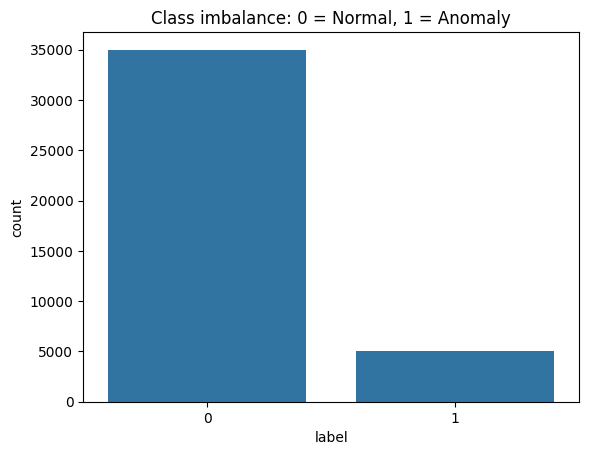

In [5]:
print("Class counts:")
display(data["label"].value_counts().rename(index={0:"Normal",1:"Anomaly"}))
print("Provided splits:")
display(pd.crosstab(data["split"], data["label"]))
print("Missing values:")
display(data.isna().sum()[lambda s: s > 0].sort_values(ascending=False))
sns.countplot(data=data, x="label")
plt.title("Class imbalance: 0 = Normal, 1 = Anomaly")
plt.show()


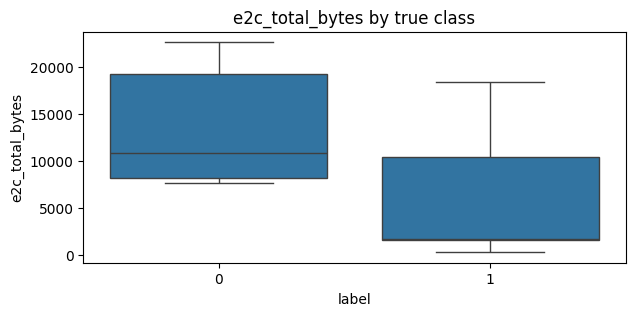

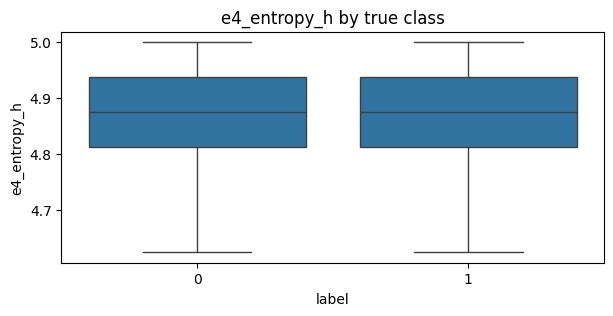

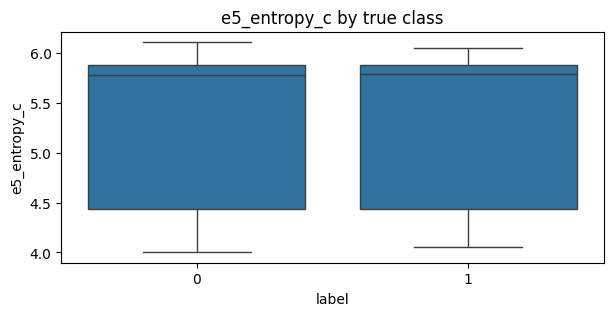

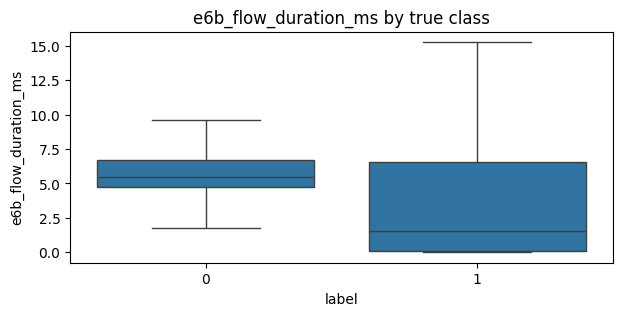

In [6]:
numeric_features = ["e2c_total_bytes", "e4_entropy_h",
                    "e5_entropy_c", "e6b_flow_duration_ms"]
for feature in numeric_features:
    fig, ax = plt.subplots(figsize=(7,3))
    sns.boxplot(data=data, x="label", y=feature, showfliers=False, ax=ax)
    ax.set_title(f"{feature} by true class")
    plt.show()


## 4. Prepare the features and provided splits
`ID`, `taxonomy`, and `split` are metadata, not predictive TLS features. `label` is the target.

In [7]:
required = {"ID", "label", "split", "taxonomy"}
assert required.issubset(data.columns), "Unexpected ML file schema"
assert data["ID"].is_unique, "Expected one row per ID"
assert set(data["split"].unique()) == {"train", "val", "test"}
assert set(data["label"].unique()) == {0, 1}

feature_cols = [c for c in data.columns if c not in required]
X = data[feature_cols].astype(float)
y = data["label"].astype(int)

masks = {s: data["split"].eq(s) for s in ("train", "val", "test")}
X_train, y_train = X.loc[masks["train"]], y.loc[masks["train"]]
X_val, y_val = X.loc[masks["val"]], y.loc[masks["val"]]
X_test, y_test = X.loc[masks["test"]], y.loc[masks["test"]]

print("Features:", len(feature_cols))
print("Train / Validation / Test:", len(X_train), len(X_val), len(X_test))


Features: 32
Train / Validation / Test: 24006 8002 8002


## 5. Train the three supervised classifiers
Each pipeline fits its imputer on **training data only**. Logistic Regression also scales its features. The other two models do not require scaling.

In [8]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
weight_ratio = neg / pos

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("classifier", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("classifier", XGBClassifier(
            n_estimators=250, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            scale_pos_weight=weight_ratio,
            eval_metric="logloss", tree_method="hist",
            n_jobs=-1, random_state=RANDOM_STATE
        ))
    ])
}
for name, model in models.items():
    model.fit(X_train, y_train)
    print("Trained:", name)


Trained: Logistic Regression
Trained: Random Forest
Trained: XGBoost


## 6. Choose a decision threshold using validation data
Use the **validation set**, not the test set, to select each model's threshold. This example chooses the threshold maximizing anomaly-class F1. In a real SOC, you might prefer a minimum recall or an alert-volume constraint.

In [9]:
def choose_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    f1 = 2 * precision[:-1] * recall[:-1] / (
        precision[:-1] + recall[:-1] + 1e-12
    )
    return float(thresholds[np.argmax(f1)])

thresholds = {}
for name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    thresholds[name] = choose_threshold(y_val, probabilities)
    print(f"{name}: validation-selected threshold = {thresholds[name]:.4f}")


Logistic Regression: validation-selected threshold = 0.8496
Random Forest: validation-selected threshold = 0.8559
XGBoost: validation-selected threshold = 0.9683


## 7. Final test evaluation
Run this section **after** model settings and thresholds are finalized. PR-AUC below uses average precision (AP).


 Logistic Regression
              precision    recall  f1-score   support

      Normal       0.97      1.00      0.99      7000
     Anomaly       1.00      0.81      0.90      1002

    accuracy                           0.98      8002
   macro avg       0.99      0.91      0.94      8002
weighted avg       0.98      0.98      0.98      8002



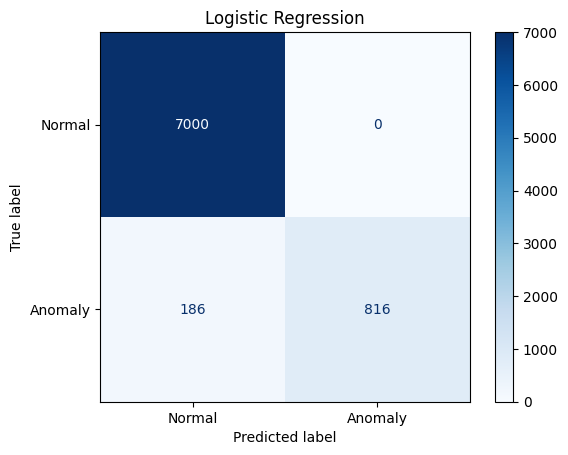


 Random Forest
              precision    recall  f1-score   support

      Normal       0.97      1.00      0.99      7000
     Anomaly       1.00      0.82      0.90      1002

    accuracy                           0.98      8002
   macro avg       0.99      0.91      0.94      8002
weighted avg       0.98      0.98      0.98      8002



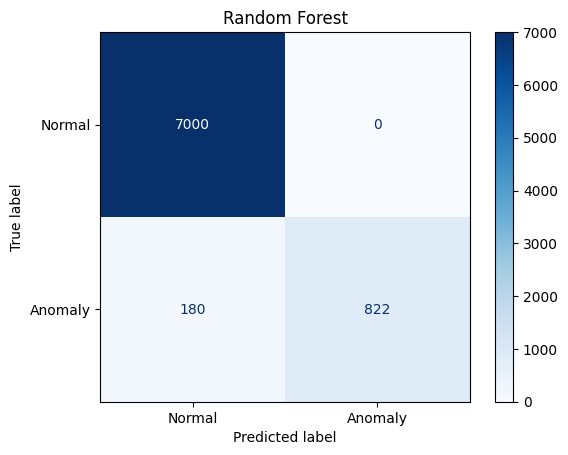


 XGBoost
              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99      7000
     Anomaly       1.00      0.82      0.90      1002

    accuracy                           0.98      8002
   macro avg       0.99      0.91      0.94      8002
weighted avg       0.98      0.98      0.98      8002



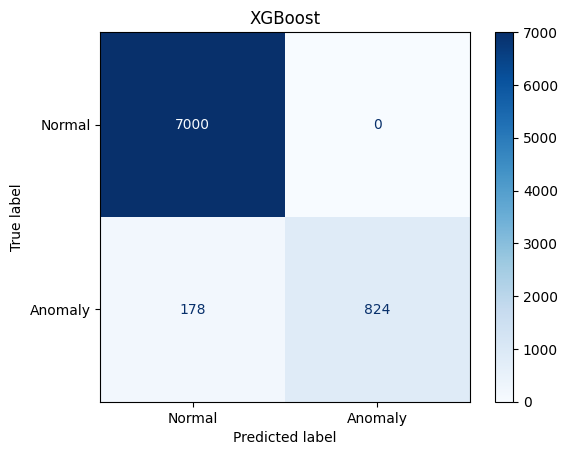

,Model,Threshold,Precision,Recall,F1,PR-AUC (AP),ROC-AUC,False positives,False negatives
2,XGBoost,0.968320,1.0,0.822355,0.902519,0.933472,0.983688,0,178
1,Random Forest,0.855921,1.0,0.820359,0.901316,0.932504,0.983445,0,180
0,Logistic Regression,0.849591,1.0,0.814371,0.897690,0.931152,0.982978,0,186


In [10]:
def metric_row(name, y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "PR-AUC (AP)": average_precision_score(y_true, prob),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "False positives": int(((pred == 1) & (y_true == 0)).sum()),
        "False negatives": int(((pred == 0) & (y_true == 1)).sum())
    }

test_probabilities = {}
test_predictions = {}
rows = []
for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= thresholds[name]).astype(int)
    test_probabilities[name] = prob
    test_predictions[name] = pred
    rows.append(metric_row(name, y_test, prob, thresholds[name]))
    print("\n", name)
    print(classification_report(y_test, pred, target_names=["Normal", "Anomaly"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Normal", "Anomaly"], cmap="Blues"
    )
    plt.title(name)
    plt.show()

results = pd.DataFrame(rows).sort_values("F1", ascending=False)
display(results)
results.to_csv("model_comparison.csv", index=False)


## 8. Check scenario-family leakage and error patterns
**Important ID formatting detail:** the ML file stores IDs without `.pcap`, while the manifest includes `.pcap`. We normalize the IDs before joining. Do not feed scenario metadata into the classifier.

In [11]:
manifest_clean = manifest.copy()
manifest_clean["join_id"] = manifest_clean["ID"].str.replace(r"\.pcap$", "", regex=True)
assert manifest_clean["join_id"].is_unique
assert data["ID"].isin(manifest_clean["join_id"]).all(), "Unmatched manifest IDs"

joined = data[["ID", "split", "label"]].merge(
    manifest_clean.drop(columns="ID"), left_on="ID", right_on="join_id",
    how="left", validate="one_to_one"
)
print("Number of scenario families:", joined["scenario_id"].nunique())
overlap = joined.groupby("scenario_id")["split"].nunique()
print("Scenario families present in multiple splits:", int((overlap > 1).sum()))
display(pd.crosstab(joined["taxonomy_class"], joined["split"]))

if (overlap > 1).any():
    print("WARNING: The provided split shares scenario families across partitions.")
    print("Treat performance as within-scenario generalization; consider a separate")
    print("scenario-held-out experiment if enough distinct families exist.")


Number of scenario families: 21
Scenario families present in multiple splits: 21


split,test,train,val
taxonomy_class,,,
ML,7000,21000,7000
Model,88,319,93
Network,278,924,298
Protocol,2,7,1
Threat,634,1756,610


Treat performance as within-scenario generalization; consider a separate
scenario-held-out experiment if enough distinct families exist.


In [12]:
# Select the highest-test-F1 model for explanation, not for claiming
# an unbiased model-selection result. Ideally select model using validation.
validation_f1 = {}
for name, model in models.items():
    p = (model.predict_proba(X_val)[:, 1] >= thresholds[name]).astype(int)
    validation_f1[name] = f1_score(y_val, p, zero_division=0)
best_name = max(validation_f1, key=validation_f1.get)
print("Selected using validation F1:", best_name)

errors = data.loc[masks["test"], ["ID", "label"]].copy()
errors["prediction"] = test_predictions[best_name]
errors["anomaly_probability"] = test_probabilities[best_name]
errors["error_type"] = np.select(
    [
        (errors.label == 0) & (errors.prediction == 1),
        (errors.label == 1) & (errors.prediction == 0)
    ],
    ["False positive", "False negative"],
    default="Correct"
)
errors = errors.merge(
    manifest_clean.drop(columns="ID"),
    left_on="ID", right_on="join_id", how="left", validate="one_to_one"
)
display(pd.crosstab(errors["subtype"], errors["error_type"]))
display(errors[errors["error_type"] != "Correct"].head(15))
errors.to_csv("test_session_predictions_with_scenarios.csv", index=False)


Selected using validation F1: Random Forest


error_type,Correct,False negative
subtype,,
baseline_normal,7000,0
data_exfil,105,0
gray_mimicry,88,0
high_jitter_classic,84,2
high_latency,105,0
high_loss,2,85
hybrid_pki,0,93
kem_mismatch,119,0
malformed_keyshare,2,0


,ID,label,prediction,anomaly_probability,error_type,scenario_id,taxonomy_class,subtype,operational_class,anomaly_label,run_idx,join_id
17,net_high_jitter_classic_run204,1,0,0.839850,False negative,net_high_jitter_classic,Network,high_jitter_classic,Classical,Anomaly,204,net_high_jitter_classic_run204
28,net_high_jitter_classic_run238,1,0,0.725835,False negative,net_high_jitter_classic,Network,high_jitter_classic,Classical,Anomaly,238,net_high_jitter_classic_run238
191,net_high_loss_pqc_run100,1,0,0.328851,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,100,net_high_loss_pqc_run100
192,net_high_loss_pqc_run11,1,0,0.384096,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,11,net_high_loss_pqc_run11
193,net_high_loss_pqc_run112,1,0,0.278006,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,112,net_high_loss_pqc_run112
194,net_high_loss_pqc_run113,1,0,0.224844,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,113,net_high_loss_pqc_run113
195,net_high_loss_pqc_run118,1,0,0.130918,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,118,net_high_loss_pqc_run118
196,net_high_loss_pqc_run124,1,0,0.236044,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,124,net_high_loss_pqc_run124
197,net_high_loss_pqc_run14,1,0,0.156119,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,14,net_high_loss_pqc_run14
198,net_high_loss_pqc_run152,1,0,0.238245,False negative,net_high_loss_pqc,Network,high_loss,Compliant_PQC,Anomaly,152,net_high_loss_pqc_run152


## 9. SHAP explanations
SHAP attributes each model prediction to input features. **SHAP is not causal proof of an attack.** The following uses a sample of test sessions to keep Colab runtime manageable. We explain the selected tree model if possible; if Logistic Regression wins, use the XGBoost model for a separate tree-based SHAP illustration.

SHAP model: Random Forest


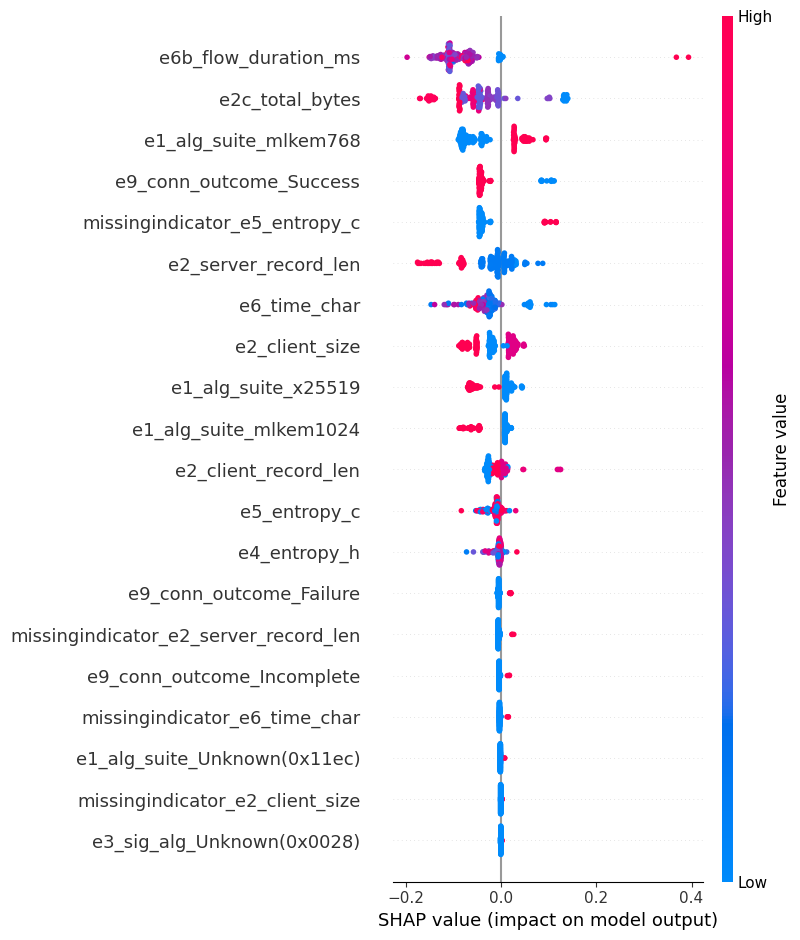

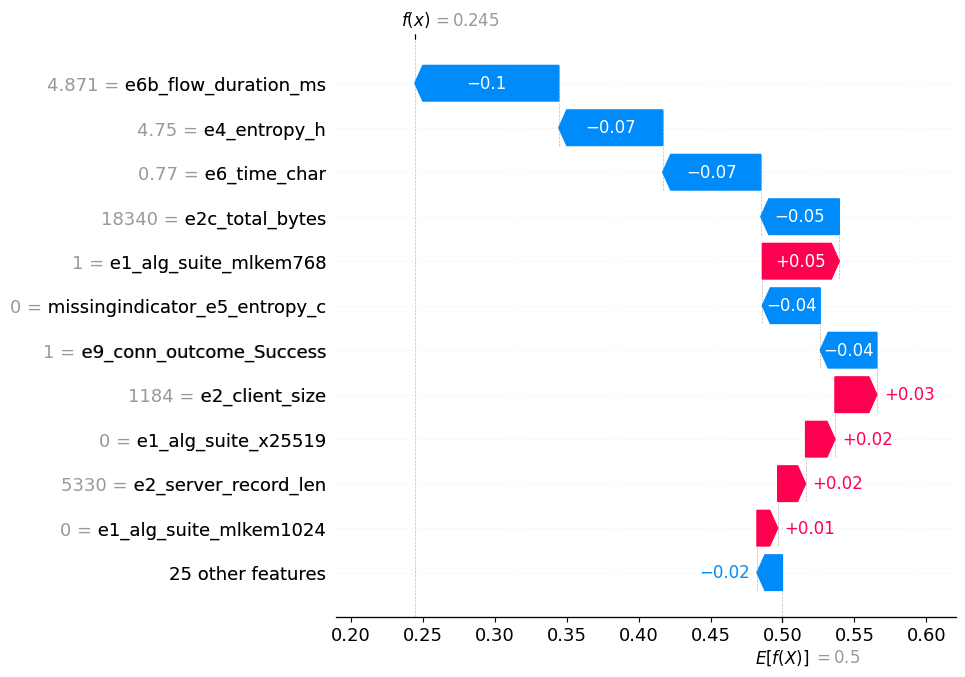

In [13]:
tree_name = best_name if best_name in ("Random Forest", "XGBoost") else "XGBoost"
tree_pipeline = models[tree_name]
sample = X_test.sample(n=min(200, len(X_test)), random_state=RANDOM_STATE)

imputer = tree_pipeline.named_steps["imputer"]
sample_transformed = imputer.transform(sample)
feature_names = list(imputer.get_feature_names_out(feature_cols))
sample_for_shap = pd.DataFrame(
    sample_transformed, columns=feature_names, index=sample.index
)

explainer = shap.TreeExplainer(tree_pipeline.named_steps["classifier"])
explanation = explainer(sample_for_shap)

# Some versions return a separate SHAP dimension for each binary class.
if explanation.values.ndim == 3:
    explanation = explanation[:, :, 1]

print("SHAP model:", tree_name)
shap.summary_plot(explanation.values, sample_for_shap, show=True)
shap.plots.waterfall(explanation[0], max_display=12)
